# Load Data & Initial Inspection


We start by loading the training and test datasets and inspecting the structure, data types, and missing values.
This helps us understand which columns require cleaning and preprocessing before encoding.

In [1]:
!pip install category_encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 6.2 MB/s eta 0:00:00


In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.9 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
import category_encoders as ce
import re
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

RANDOM_STATE = 42
sns.set_style("whitegrid")

In [4]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [5]:
display(train.head())
print(train.info())
train.isnull().sum()

        brand                      model    year  mileage  \
0       Mazda               CX-9 Touring  2022.0   6580.0   
1        Alfa  Romeo Stelvio 4DR SUV AWD  2018.0  62717.0   
2   Chevrolet  Silverado 1500 Limited LT  2022.0  15463.0   
3        Land  Rover Range Rover P400 SE  2022.0   1281.0   
4  Mitsubishi     Outlander Sport 2.0 SE  2021.0  36727.0   

                                      engine  engine_size       transmission  \
0                 2.5L I4 16V GDI DOHC Turbo          2.5  6-Speed Automatic   
1  Twin Turbo Premium Unleaded V-6 2.9 L/176          2.9          Automatic   
2                        5.3L V8 16V GDI OHV          5.3          Automatic   
3                 3.0L I6 24V GDI DOHC Turbo          3.0          Automatic   
4                      2.0L I4 16V MPFI DOHC          2.0      Automatic CVT   

   automatic_transmission fuel_type         drivetrain  ...  leather_seats  \
0                     1.0  Gasoline   Four-wheel Drive  ...            1.0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19109 entries, 0 to 19108
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   brand                        19107 non-null  object 
 1   model                        19107 non-null  object 
 2   year                         19107 non-null  float64
 3   mileage                      19107 non-null  float64
 4   engine                       19062 non-null  object 
 5   engine_size                  17860 non-null  float64
 6   transmission                 19004 non-null  object 
 7   automatic_transmission       19107 non-null  float64
 8   fuel_type                    19107 non-null  object 
 9   drivetrain                   19107 non-null  object 
 10  min_mpg                      16103 non-null  float64
 11  max_mpg                      16103 non-null  float64
 12  damaged                      18940 non-null  float64
 13  first_owner     

brand                             2
model                             2
year                              2
mileage                           2
engine                           47
engine_size                    1249
transmission                    105
automatic_transmission            2
fuel_type                         2
drivetrain                        2
min_mpg                        3006
max_mpg                        3006
damaged                         169
first_owner                     306
personal_using                  189
turbo                             2
alloy_wheels                      2
adaptive_cruise_control           2
navigation_system                 2
power_liftgate                    2
backup_camera                     2
keyless_start                     2
remote_start                      2
sunroof/moonroof                  2
automatic_emergency_braking       2
stability_control                 2
leather_seats                     2
memory_seat                 

**Clean Price Column**

The price column contains:
missing values
text values ("ot Priced", "$29,995", etc.)
commas and non-numeric characters
We clean it by:
Removing invalid rows,
Removing symbols,
Converting to float.

In [6]:
def clean_price(df):
    # remove non-numeric placeholders
    df = df[df['price'].notna()]
    df = df[~df['price'].astype(str).str.contains("ot|Call|—", case=False, na=False)]

    # remove currency symbols & commas
    df['price'] = (
        df['price'].astype(str)
        .str.replace(r"[^0-9.]", "", regex=True)
        .replace("", np.nan)
        .astype(float)
    )
    return df

train = clean_price(train)
test = clean_price(test)


# **Handle Missing Values**


We fix missing values for:
drivetrain,
transmission,
fuel_type,
engine,
engine_size,
mpg columns,
We fill categorical values with "Unknown"
And numerical columns with median values.

In [7]:
# Identify columns with nulls
null_counts = train.isnull().sum()
categorical_fill = null_counts[(null_counts > 0) & (train.dtypes == 'object')].index.tolist()
numeric_fill = null_counts[(null_counts > 0) & (train.dtypes != 'object')].index.tolist()

print("Categorical columns to fill:", categorical_fill)
print("Numeric columns to fill:", numeric_fill)


#  FILL CATEGORICAL COLUMNS

for col in categorical_fill:
    # Train
    train[col] = train[col].replace("", np.nan).fillna("Unknown")

    # Test (only if column exists)
    if col in test.columns:
        test[col] = test[col].replace("", np.nan).fillna("Unknown")



#  FILL NUMERIC COLUMNS

for col in numeric_fill:
    # Computing median using TRAIN ONLY
    median = train[col].replace("", np.nan).astype(float).median()

    # Train
    train[col] = train[col].replace("", np.nan).astype(float).fillna(median)

    # Test
    if col in test.columns:
        test[col] = test[col].replace("", np.nan).astype(float).fillna(median)

print("Missing value handling complete.")


Categorical columns to fill: ['engine', 'transmission', 'interior_color', 'exterior_color']
Numeric columns to fill: ['engine_size', 'min_mpg', 'max_mpg', 'damaged', 'first_owner', 'personal_using']
Missing value handling complete.


In [8]:
train.isnull().sum()

brand                          0
model                          0
year                           0
mileage                        0
engine                         0
engine_size                    0
transmission                   0
automatic_transmission         0
fuel_type                      0
drivetrain                     0
min_mpg                        0
max_mpg                        0
damaged                        0
first_owner                    0
personal_using                 0
turbo                          0
alloy_wheels                   0
adaptive_cruise_control        0
navigation_system              0
power_liftgate                 0
backup_camera                  0
keyless_start                  0
remote_start                   0
sunroof/moonroof               0
automatic_emergency_braking    0
stability_control              0
leather_seats                  0
memory_seat                    0
third_row_seating              0
apple_car_play/android_auto    0
bluetooth 

# **Handling outliers**

In [9]:
#  Separating numeric and categorical features
numeric_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

 OUTLIER DETECTION AND HANDLING 
 Removed 'price' from outlier handling 

Features to handle outliers: ['year', 'mileage', 'engine_size', 'automatic_transmission', 'min_mpg', 'max_mpg', 'damaged', 'first_owner', 'personal_using', 'turbo', 'alloy_wheels', 'adaptive_cruise_control', 'navigation_system', 'power_liftgate', 'backup_camera', 'keyless_start', 'remote_start', 'sunroof/moonroof', 'automatic_emergency_braking', 'stability_control', 'leather_seats', 'memory_seat', 'third_row_seating', 'apple_car_play/android_auto', 'bluetooth', 'usb_port', 'heated_seats']

 Visualizing outliers BEFORE handling 


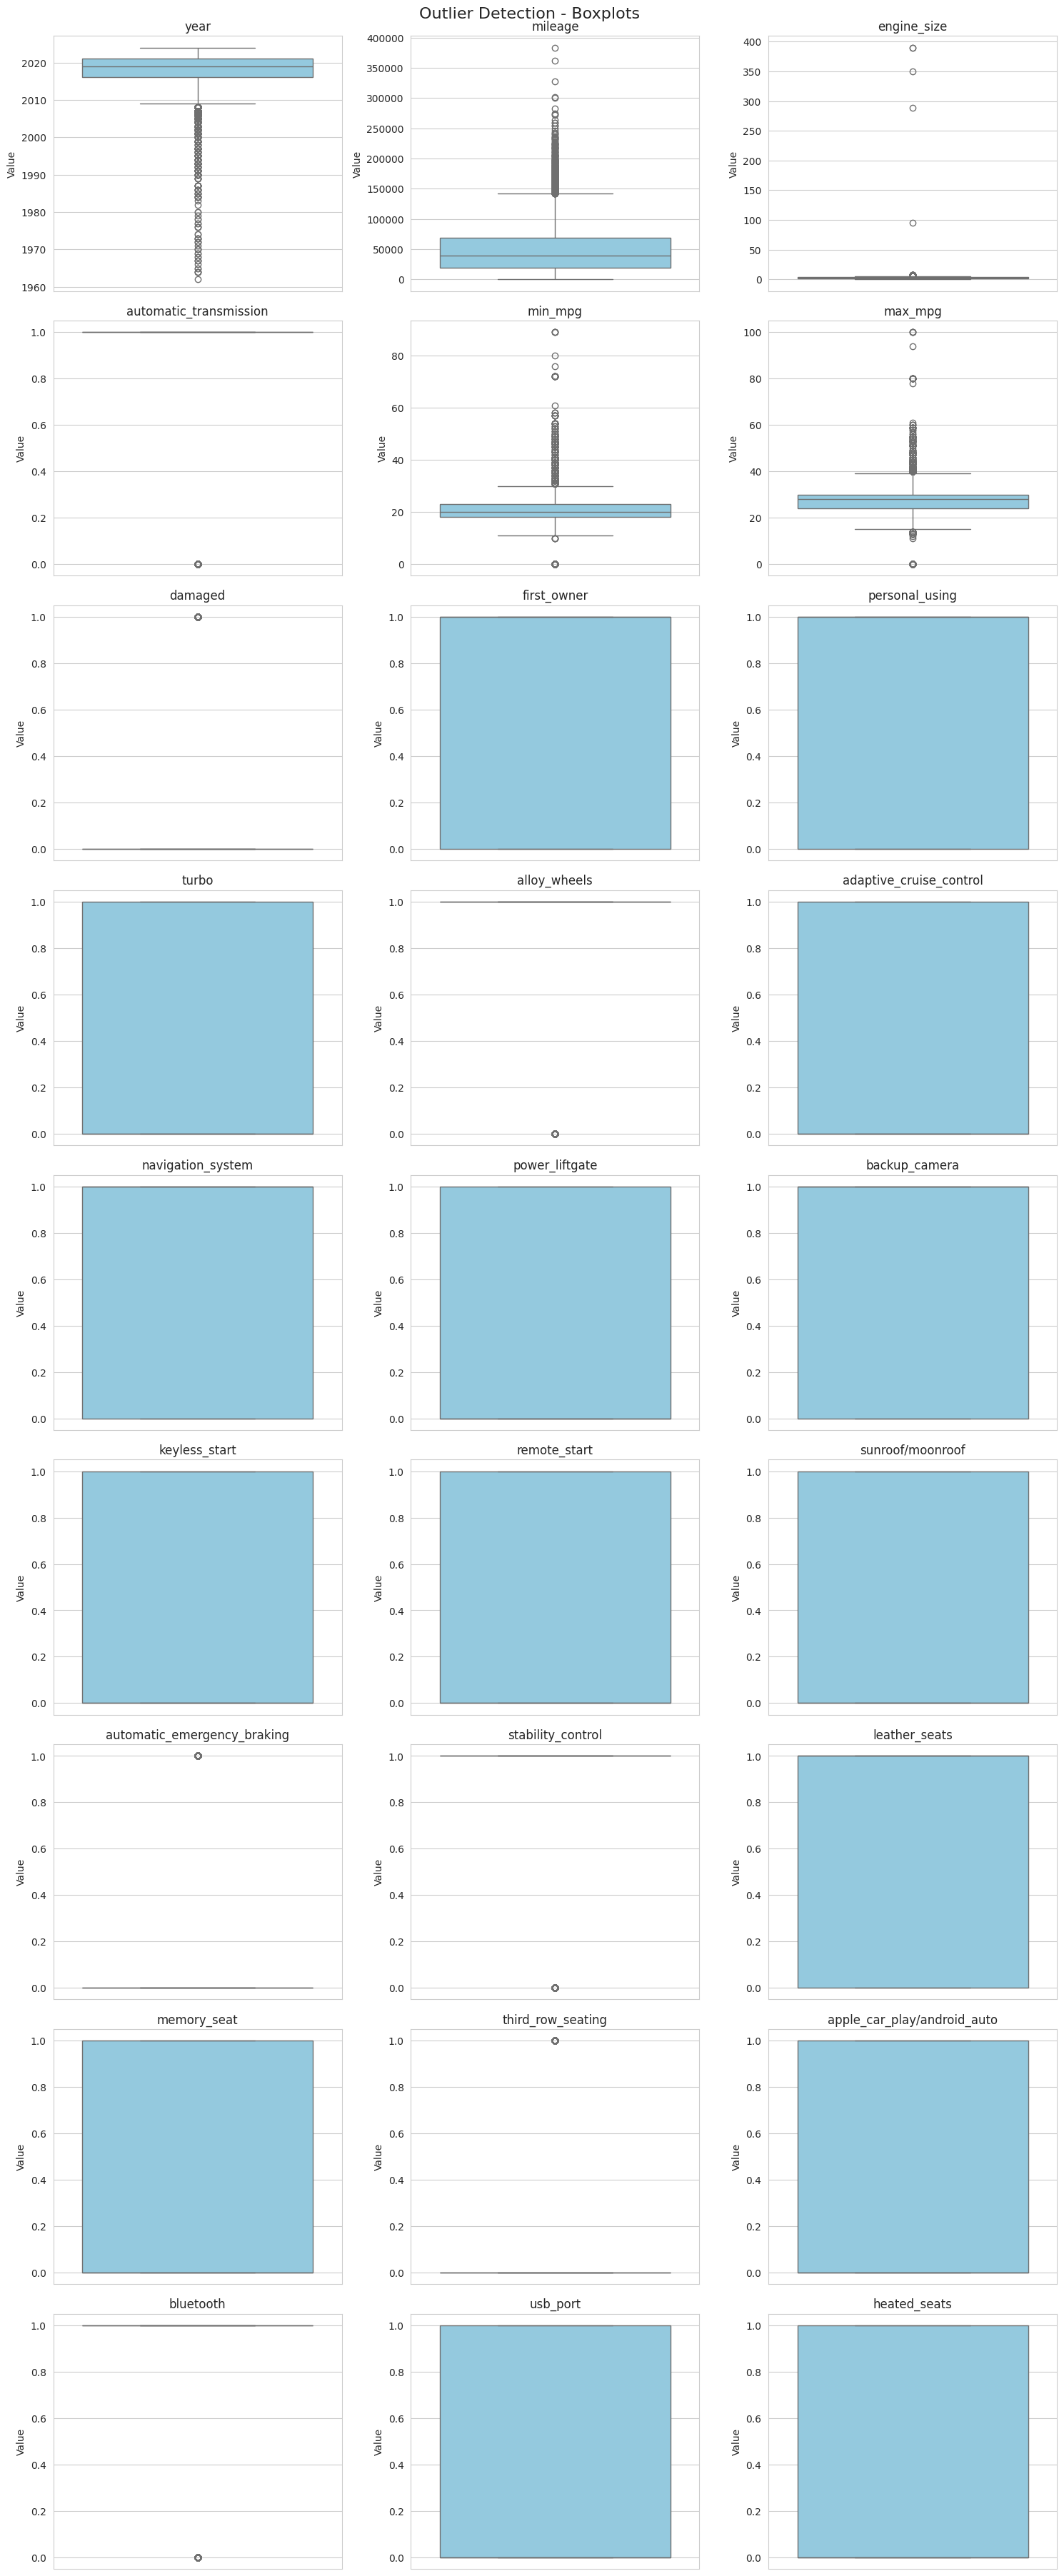

In [10]:
from scipy import stats

print(" OUTLIER DETECTION AND HANDLING ")

# we Separated price from numeric columns because We should NOT handle outliers in the target variable!
numeric_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Removing 'price' from numeric_cols - we don't want to cap the target!
if 'price' in numeric_cols:
    numeric_cols.remove('price')
    print(f" Removed 'price' from outlier handling ")

print(f"\nFeatures to handle outliers: {numeric_cols}")

#  Visualize outliers first
def visualize_outliers(data, numeric_cols, n_cols=3):
    """Visualize outliers using boxplots"""
    n_features = len(numeric_cols)
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
    axes = axes.flatten() if n_features > 1 else [axes]

    for idx, col in enumerate(numeric_cols):
        sns.boxplot(data=data, y=col, ax=axes[idx], color='skyblue')
        axes[idx].set_title(f'{col}', fontsize=12)
        axes[idx].set_ylabel('Value')

    # Hide empty subplots
    for idx in range(n_features, len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.suptitle('Outlier Detection - Boxplots ', fontsize=16, y=1.001)
    plt.show()

# Visualize before handling
print("\n Visualizing outliers BEFORE handling ")
visualize_outliers(train, numeric_cols)


In [11]:
def detect_outliers_iqr(data, column):
    """Detect outliers using IQR method"""
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers.index, lower_bound, upper_bound

In [12]:
outlier_summary = {}
for col in numeric_cols:
    iqr_outliers, lower, upper = detect_outliers_iqr(train, col)

    outlier_summary[col] = {
        'iqr_count': len(iqr_outliers),
        'iqr_percentage': len(iqr_outliers) / len(train) * 100,
        'lower_bound': lower,
        'upper_bound': upper
    }

    print(f"\n{col}:")
    print(f"  IQR outliers: {len(iqr_outliers)} ({len(iqr_outliers)/len(train)*100:.2f}%)")
    print(f"  IQR bounds: [{lower:.2f}, {upper:.2f}]")



year:
  IQR outliers: 837 (4.39%)
  IQR bounds: [2008.50, 2028.50]

mileage:
  IQR outliers: 463 (2.43%)
  IQR bounds: [-54259.25, 141890.75]

engine_size:
  IQR outliers: 567 (2.97%)
  IQR bounds: [-0.25, 5.75]

automatic_transmission:
  IQR outliers: 1577 (8.27%)
  IQR bounds: [1.00, 1.00]

min_mpg:
  IQR outliers: 849 (4.45%)
  IQR bounds: [10.50, 30.50]

max_mpg:
  IQR outliers: 733 (3.84%)
  IQR bounds: [15.00, 39.00]

damaged:
  IQR outliers: 4109 (21.54%)
  IQR bounds: [0.00, 0.00]

first_owner:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

personal_using:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

turbo:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

alloy_wheels:
  IQR outliers: 1880 (9.86%)
  IQR bounds: [1.00, 1.00]

adaptive_cruise_control:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

navigation_system:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

power_liftgate:
  IQR outliers: 0 (0.00%)
  IQR bounds: [-1.50, 2.50]

backup_

In [13]:
def cap_outliers(data, columns, method='iqr'):
    """Cap outliers at lower and upper bounds"""
    data_copy = data.copy()

    for col in columns:
        if method == 'iqr':
            Q1 = data_copy[col].quantile(0.25)
            Q3 = data_copy[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
        elif method == 'percentile':
            lower_bound = data_copy[col].quantile(0.01)
            upper_bound = data_copy[col].quantile(0.99)

        # Cap the values
        original_outliers = ((data_copy[col] < lower_bound) | (data_copy[col] > upper_bound)).sum()
        data_copy[col] = data_copy[col].clip(lower=lower_bound, upper=upper_bound)

        print(f"{col}: Capped {original_outliers} outliers")

    return data_copy

# Apply capping to FEATURES ONLY
train_capped = cap_outliers(train, numeric_cols, method='iqr')


year: Capped 837 outliers
mileage: Capped 463 outliers
engine_size: Capped 567 outliers
automatic_transmission: Capped 1577 outliers
min_mpg: Capped 849 outliers
max_mpg: Capped 733 outliers
damaged: Capped 4109 outliers
first_owner: Capped 0 outliers
personal_using: Capped 0 outliers
turbo: Capped 0 outliers
alloy_wheels: Capped 1880 outliers
adaptive_cruise_control: Capped 0 outliers
navigation_system: Capped 0 outliers
power_liftgate: Capped 0 outliers
backup_camera: Capped 0 outliers
keyless_start: Capped 0 outliers
remote_start: Capped 0 outliers
sunroof/moonroof: Capped 0 outliers
automatic_emergency_braking: Capped 3330 outliers
stability_control: Capped 958 outliers
leather_seats: Capped 0 outliers
memory_seat: Capped 0 outliers
third_row_seating: Capped 2840 outliers
apple_car_play/android_auto: Capped 0 outliers
bluetooth: Capped 2470 outliers
usb_port: Capped 0 outliers
heated_seats: Capped 0 outliers


Visualizing outliers AFTER handling


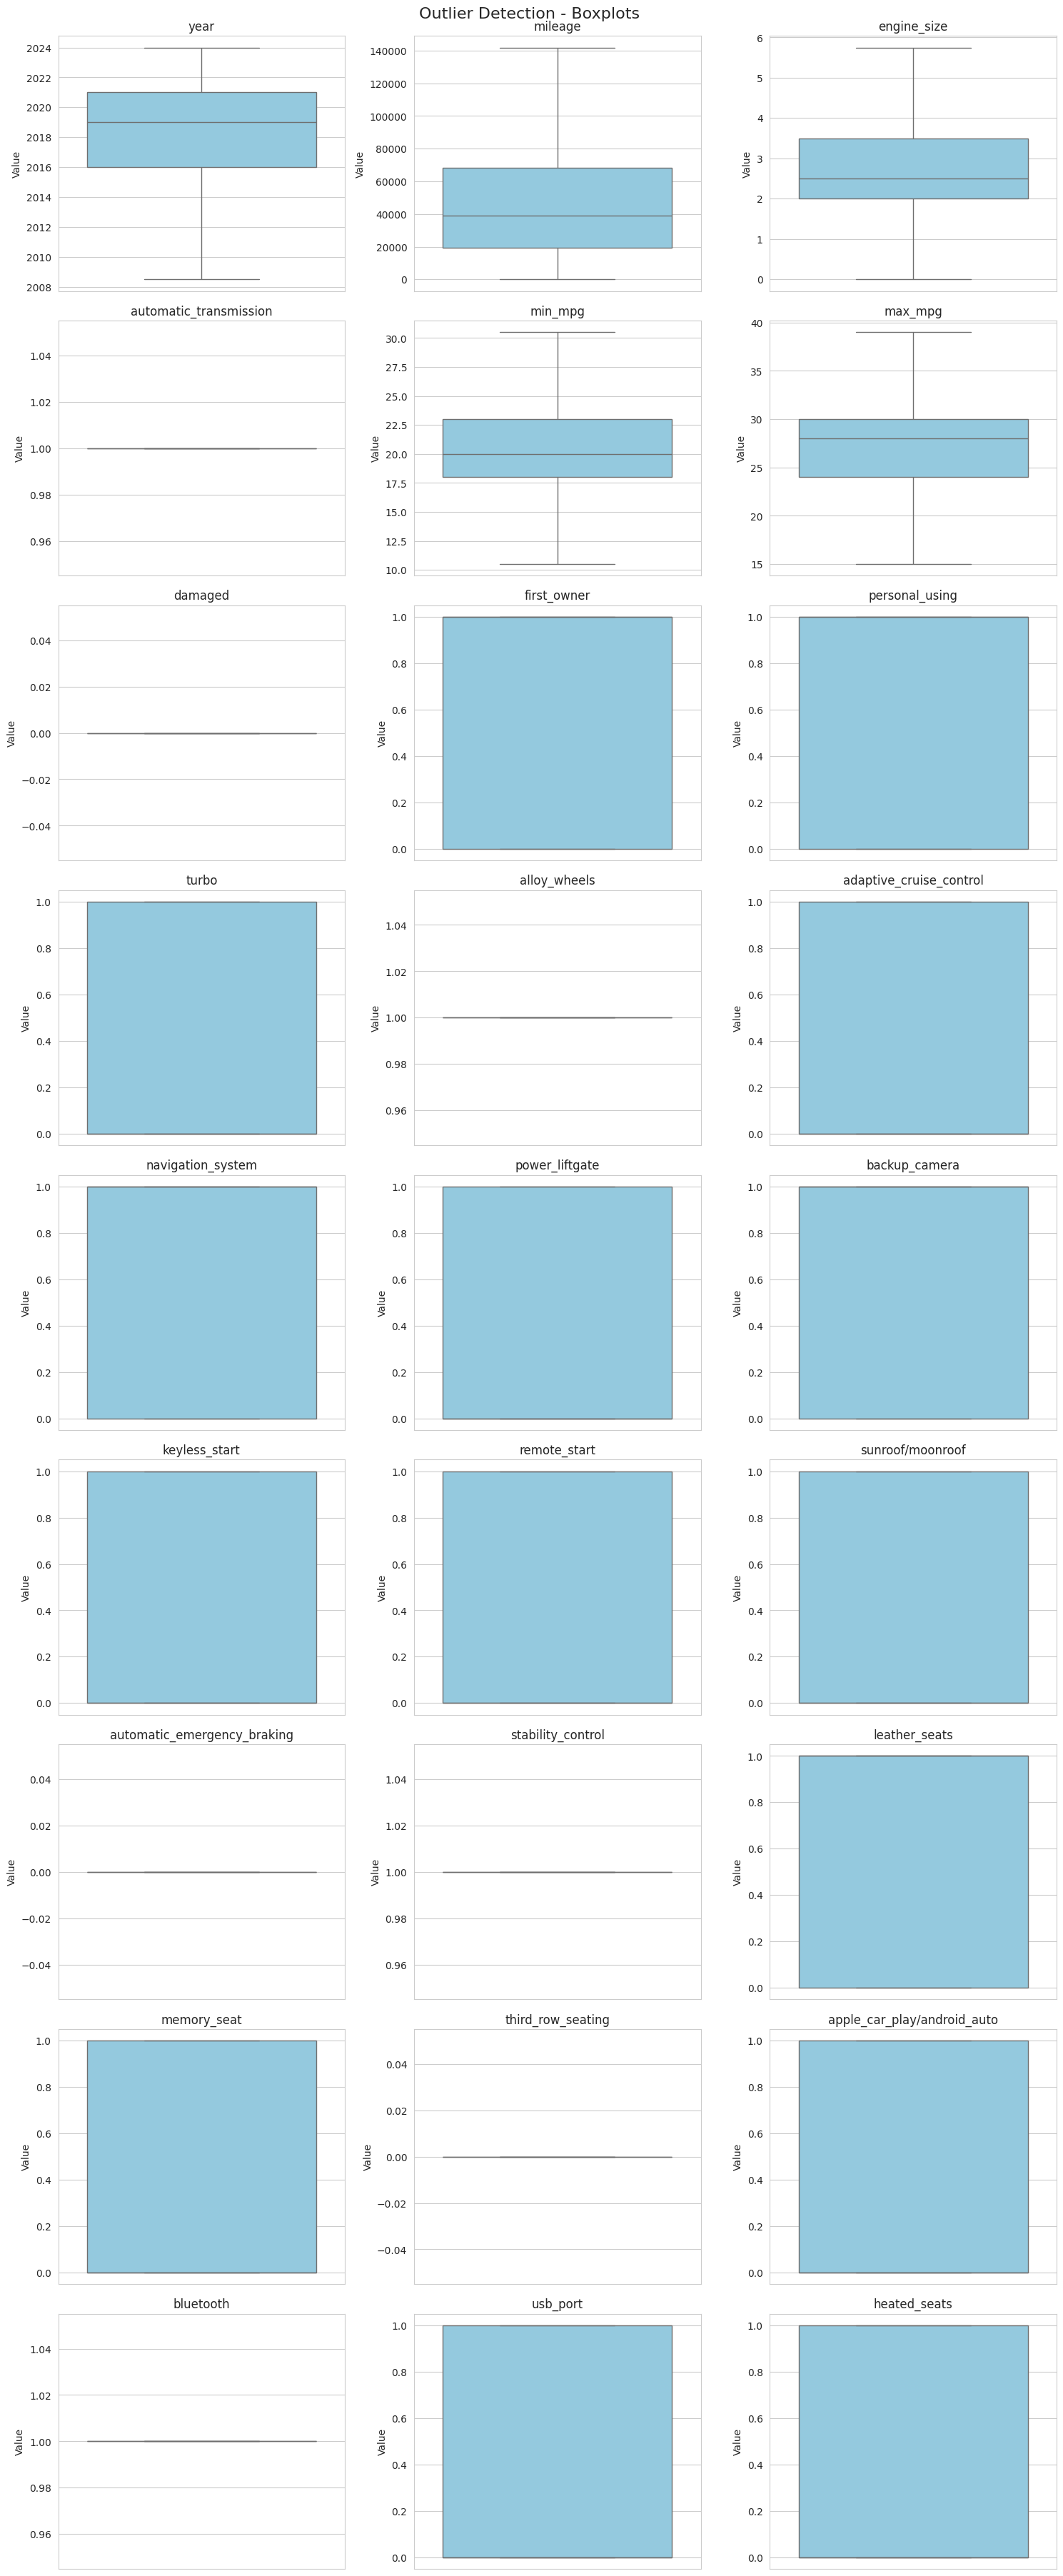

In [14]:
train = train_capped

print("Visualizing outliers AFTER handling")
visualize_outliers(train, numeric_cols)

# **Feature Engineering**

# Normalize  Car Color



Car interior and exterior colors contain alot of variations, e.g., "Midnight Black", "Obsidian Black Metallic", "Jet Black".  
If we encode each variant as-is, we risk creating a very high-dimensional sparse feature set, which can risk errors regression models.  

To handle this:  
1. Extract the base color (e.g., "Black", "White", "Red").  
2. Detect metallic finish and create a separate binary feature.  

This approach reduces dimensionality while retaining meaningful information that can affect price.  
After normalization, we will one-hot encode the base color and include the metallic flag as a feature.


In [15]:
# Normalize Car Color in Train and Test Sets

#To ensure consistency, the color normalization function is applied to both train and test sets.
#This way, the base color and metallic information are processed the same way in both datasets, avoiding unseen or mismatched categories during modeling.

# Function to normalize color and separate metallic flag
def normalize_color(color):
    color = str(color).lower()
    base_colors = ['black', 'white', 'red', 'blue', 'silver', 'gray', 'grey', 'green', 'yellow', 'orange', 'brown', 'beige', 'almond', 'ebony', 'cognac', 'carbon', 'nero', 'saddle', 'light oyster']

    metallic = 1 if 'metallic' in color or 'mica' in color or 'clearcoat' in color or 'pearl' in color or 'coat' in color else 0
    base_color = next((c for c in base_colors if c in color), 'other')

    return pd.Series([base_color.capitalize(), metallic])

# Apply to train set
for col in ['interior_color', 'exterior_color']:
    train[[f'{col}_base', f'{col}_metallic']] = train[col].apply(normalize_color)

# Apply to test set
for col in ['interior_color', 'exterior_color']:
    test[[f'{col}_base', f'{col}_metallic']] = test[col].apply(normalize_color)



In [16]:
train.head()

        brand                      model    year  mileage  \
0       Mazda               CX-9 Touring  2022.0   6580.0   
1        Alfa  Romeo Stelvio 4DR SUV AWD  2018.0  62717.0   
2   Chevrolet  Silverado 1500 Limited LT  2022.0  15463.0   
3        Land  Rover Range Rover P400 SE  2022.0   1281.0   
4  Mitsubishi     Outlander Sport 2.0 SE  2021.0  36727.0   

                                      engine  engine_size       transmission  \
0                 2.5L I4 16V GDI DOHC Turbo          2.5  6-Speed Automatic   
1  Twin Turbo Premium Unleaded V-6 2.9 L/176          2.9          Automatic   
2                        5.3L V8 16V GDI OHV          5.3          Automatic   
3                 3.0L I6 24V GDI DOHC Turbo          3.0          Automatic   
4                      2.0L I4 16V MPFI DOHC          2.0      Automatic CVT   

   automatic_transmission fuel_type         drivetrain  ...  bluetooth  \
0                     1.0  Gasoline   Four-wheel Drive  ...        1.0   
1   

# **Simplify Transmission Column**

Transmission strings can have many variants, such as "8-Speed Automatic", "Automatic CVT", "Dual-Clutch", and "Manual".  
We reduce them to 5 clean categories, To make it manageable for modeling while retaining important info:  
1. Map transmissions to 5 main categories: Automatic, CVT,Dual-Clutch, Manual, Other.  
2. Extract the **number of gears** from the string when available (e.g., "8-Speed" : 8).  

This reduces sparsity and ensures the model can capture key differences in transmission types.


In [17]:
import re

# Function to simplify transmission and extract gears
def simplify_transmission(trans):
    trans_str = str(trans).lower()

    # Simplify type
    if 'automatic cvt' in trans_str or 'cvt' in trans_str:
        trans_type = 'CVT'
    elif 'dual-clutch' in trans_str:
        trans_type = 'Dual-Clutch'
    elif 'manual' in trans_str:
        trans_type = 'Manual'
    elif 'automatic' in trans_str:
        trans_type = 'Automatic'
    else:
        trans_type = 'Other'

    # Extract number of gears if present
    gears_search = re.search(r'(\d+)-speed', trans_str)
    gears = int(gears_search.group(1)) if gears_search else None

    return pd.Series([trans_type, gears])

# Apply to train set
train[['transmission_type', 'gears']] = train['transmission'].apply(simplify_transmission)

# Apply to test set
test[['transmission_type', 'gears']] = test['transmission'].apply(simplify_transmission)


In [18]:
train.head(10)

        brand                      model    year  mileage  \
0       Mazda               CX-9 Touring  2022.0   6580.0   
1        Alfa  Romeo Stelvio 4DR SUV AWD  2018.0  62717.0   
2   Chevrolet  Silverado 1500 Limited LT  2022.0  15463.0   
3        Land  Rover Range Rover P400 SE  2022.0   1281.0   
4  Mitsubishi     Outlander Sport 2.0 SE  2021.0  36727.0   
5        FIAT                  500 Sport  2012.0  83908.0   
6         Kia               Carnival LXS  2022.0  43705.0   
7        Audi           SQ5 3.0T Premium  2022.0   5922.0   
8       Honda      Pilot Special Edition  2021.0  51299.0   
9        Jeep    Grand Cherokee Altitude  2019.0  36120.0   

                                      engine  engine_size       transmission  \
0                 2.5L I4 16V GDI DOHC Turbo          2.5  6-Speed Automatic   
1  Twin Turbo Premium Unleaded V-6 2.9 L/176          2.9          Automatic   
2                        5.3L V8 16V GDI OHV          5.3          Automatic   
3       

In [19]:
test.head(10)

      brand                          model    year  mileage  \
0      FIAT               124 Spider Lusso  2020.0  30830.0   
1     Lexus                RX 450h F Sport  2019.0  58274.0   
2       Kia                    Stinger GT1  2018.0  69303.0   
3      MINI           Convertible Cooper S  2023.0   5026.0   
4    Nissan                       Murano S  2018.0  61180.0   
5    Toyota           Highlander Hybrid LE  2022.0  52250.0   
6  Cadillac        Escalade Sport Platinum  2021.0  29245.0   
7  Cadillac         CT5 Premium Luxury AWD  2020.0  16883.0   
8      Land  Rover Range Rover Evoque Pure  2013.0  86610.0   
9     Lexus                 IS 350 F Sport  2023.0   2272.0   

                                              engine  engine_size  \
0                        1.4L I4 16V MPFI SOHC Turbo          1.4   
1                        3.5L V6 24V PDI DOHC Hybrid          3.5   
2                    3.3L V6 24V GDI DOHC Twin Turbo          3.3   
3                         2.0L

### handling missing values on the 'gears' column by filling missing values using a typical number of gears based on the transmission type, which is more realistic for cars.

In [20]:
# Define typical number of gears for each transmission type
gear_map = {
    'Automatic': 6,
    'CVT': 1,# For CVT, gears are set to 1 as a placeholder since CVTs have no fixed gears; other types use typical gear counts.
    'Dual-Clutch': 7,
    'Manual': 5,
    'Other': 6
}

# Impute missing gears in train set
train['gears'] = train.apply(
    lambda row: row['gears'] if pd.notna(row['gears']) else gear_map[row['transmission_type']], axis=1
)

# Impute missing gears in test set
test['gears'] = test.apply(
    lambda row: row['gears'] if pd.notna(row['gears']) else gear_map[row['transmission_type']], axis=1
)


In [21]:
train['gears'].isnull().sum()

np.int64(0)

In [22]:
#Engine parsing
def parse_engine(engine_str):
    engine_str = str(engine_str)
    liter_search = re.search(r'(\d+(\.\d+)?)L', engine_str)
    engine_liter = float(liter_search.group(1)) if liter_search else None
    cyl_search = re.search(r'(I|V)(\d+)', engine_str)
    cylinders = int(cyl_search.group(2)) if cyl_search else None
    turbo_flag = 1 if re.search(r'(Turbo|Supercharged)', engine_str, re.I) else 0
    valves_search = re.search(r'(\d+)V', engine_str)
    valves = int(valves_search.group(1)) if valves_search else None
    return pd.Series([engine_liter, cylinders, turbo_flag, valves])

train[['engine_liter', 'cylinders', 'engine_turbo', 'valves']] = train['engine'].apply(parse_engine)
test[['engine_liter', 'cylinders', 'engine_turbo', 'valves']] = test['engine'].apply(parse_engine)

# Drop original 'engine' column
train = train.drop(columns=['engine'])
test = test.drop(columns=['engine'])

##   Log Transforming the Price Column



The price values in this dataset range from around \$9,000 up to more than \$250,000.  
This creates a **highly Imbalanced distribution**, which makes it difficult for many machine learning models to learn stable patterns.

To fix this, we apply a **logarithmic transformation** to the price column:

- It compresses very large values.
- It makes the distribution more normal (less Imbalanced)..
- It improves performance for regression models like Linear Regression.

During training, the model will predict the **log of the price**, not the raw price.  
After prediction, we simply convert the values back to real prices using:predicted_price = exp(predicted_log_price)



In [23]:
#This allows us to enjoy the modeling benefits of the log transform while still reporting final predictions in actual dollar values.
train['price_log'] = np.log1p(train['price'])  # log1p handles zeros better
test['price_log'] = np.log1p(test['price'])

In [24]:
# 1. CHECK the PRICE_LOG DISTRIBUTION
print(train['price_log'].describe())
print(f"Max price_log: {train['price_log'].max()}")
print(f"Min price_log: {train['price_log'].min()}")

# 2. Removing EXTREME PRICE OUTLIERS BEFORE LOG TRANSFORM
train = train[(train['price'] > 1000) & (train['price'] < 200000)]  # Reasonable car prices
test = test[(test['price'] > 1000) & (test['price'] < 200000)]

# 3. THEN we do LOG TRANSFORM
train['price_log'] = np.log1p(train['price'])
test['price_log'] = np.log1p(test['price'])


count    19075.000000
mean        10.309886
std          0.631879
min          7.310550
25%          9.942612
50%         10.341613
75%         10.690831
max         14.375127
Name: price_log, dtype: float64
Max price_log: 14.375126917328105
Min price_log: 7.310550158534422


In [25]:
compare_price = train[['price', 'price_log']]
print(compare_price)

          price  price_log
0       36789.0  10.512981
1       39993.0  10.596485
2       46986.0  10.757626
3      141999.0  11.863582
4       21595.0   9.980263
...         ...        ...
19104   30023.0  10.309752
19105   42500.0  10.657283
19106   43999.0  10.691945
19107   26998.0  10.203555
19108   15382.0   9.641018

[18984 rows x 2 columns]


In [26]:
compare_price = test[['price', 'price_log']]
print(compare_price)

        price  price_log
0     26500.0  10.184938
1     36987.0  10.518349
2     26997.0  10.203518
3     37923.0  10.543339
4     20490.0   9.927741
...       ...        ...
4773  92995.0  11.440312
4774  49850.0  10.816794
4775  15595.0   9.654770
4776  34321.0  10.443542
4777  38900.0  10.568775

[4749 rows x 2 columns]


# **Visualizing Cardinality for each categorical feature**

 CARDINALITY ANALYSIS OF CATEGORICAL FEATURES 

Total categorical columns: 10

 CARDINALITY SUMMARY 
             Column  Unique Values  Total Rows  Cardinality %
              model           3473       18984      18.294353
     exterior_color           1927       18984      10.150653
     interior_color            952       18984       5.014749
       transmission            189       18984       0.995575
              brand             25       18984       0.131690
interior_color_base             20       18984       0.105352
exterior_color_base             18       18984       0.094817
          fuel_type             10       18984       0.052676
         drivetrain              5       18984       0.026338
  transmission_type              5       18984       0.026338


 CARDINALITY CATEGORIES 

 LOW Cardinality (≤10 unique values): 3 columns
   - fuel_type: 10 unique values
     Top values: ['Gasoline', 'Hybrid', 'Electric']
   - drivetrain: 5 unique values
     Top values: ['Four

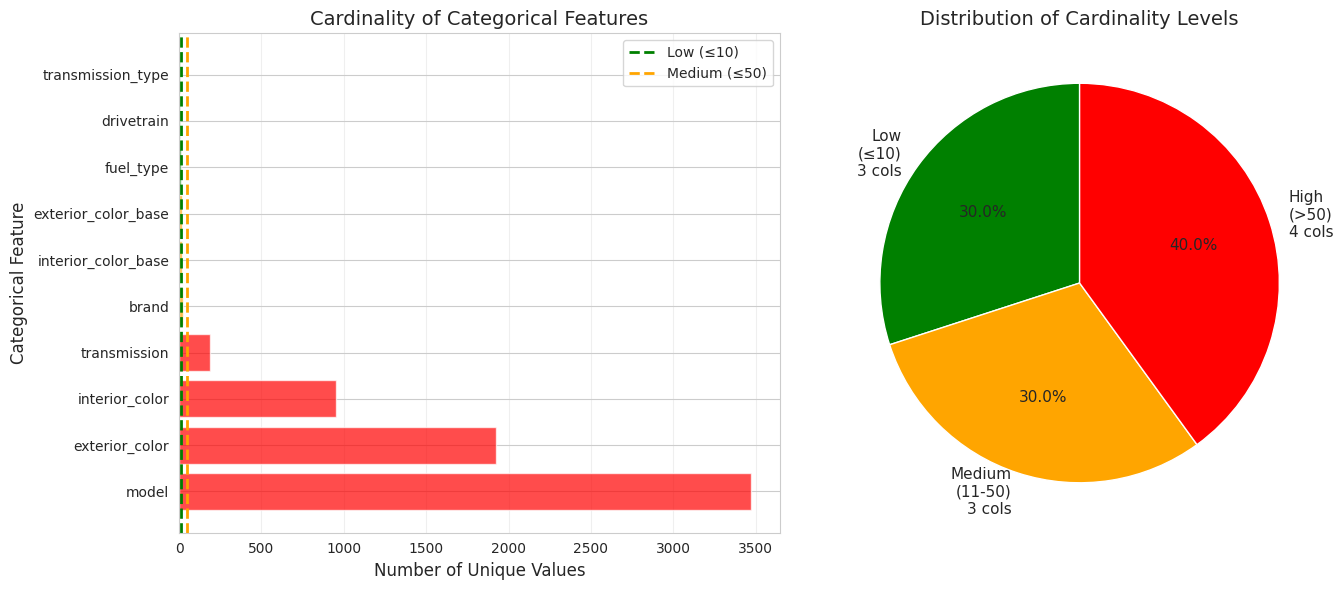



 DETAILED CARDINALITY BREAKDOWN 

Column: brand
Unique Values: 25
Percentage: 0.13%

Top 10 most frequent values:
  Audi: 855 (4.50%)
  Hyundai: 840 (4.42%)
  Ford: 834 (4.39%)
  Volvo: 831 (4.38%)
  Volkswagen: 811 (4.27%)
  Jaguar: 808 (4.26%)
  FIAT: 805 (4.24%)
  Honda: 803 (4.23%)
  Cadillac: 799 (4.21%)
  Nissan: 795 (4.19%)

Column: model
Unique Values: 3473
Percentage: 18.29%

Top 10 most frequent values:
  Romeo Giulia Ti: 169 (0.89%)
  Romeo Stelvio Ti: 160 (0.84%)
  500 Pop: 129 (0.68%)
  Ghibli S Q4: 109 (0.57%)
  Romeo Giulia Base: 107 (0.56%)
  Romeo Stelvio Base: 107 (0.56%)
  Countryman Cooper S ALL4: 95 (0.50%)
  Hardtop Cooper S: 92 (0.48%)
  500e Battery Electric: 84 (0.44%)
  GX 460 Base: 83 (0.44%)

Column: transmission
Unique Values: 189
Percentage: 1.00%

Top 10 most frequent values:
  8-Speed Automatic: 5395 (28.42%)
  6-Speed Automatic: 3102 (16.34%)
  Automatic: 2728 (14.37%)
  Automatic CVT: 1583 (8.34%)
  9-Speed Automatic: 1031 (5.43%)
  7-Speed Automatic

In [27]:
print(" CARDINALITY ANALYSIS OF CATEGORICAL FEATURES \n")

# Get categorical columns
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

print(f"Total categorical columns: {len(categorical_cols)}\n")

#  Calculate cardinality for each column
cardinality_info = {}

for col in categorical_cols:
    unique_count = train[col].nunique()
    total_count = len(train)
    percentage = (unique_count / total_count) * 100

    cardinality_info[col] = {
        'unique_values': unique_count,
        'total_rows': total_count,
        'percentage': percentage,
        'sample_values': train[col].value_counts().head(5).to_dict()
    }

# Convert to DataFrame for better display
cardinality_df = pd.DataFrame({
    'Column': categorical_cols,
    'Unique Values': [cardinality_info[col]['unique_values'] for col in categorical_cols],
    'Total Rows': [cardinality_info[col]['total_rows'] for col in categorical_cols],
    'Cardinality %': [cardinality_info[col]['percentage'] for col in categorical_cols]
})

# Sort by unique values
cardinality_df = cardinality_df.sort_values('Unique Values', ascending=False).reset_index(drop=True)

print(" CARDINALITY SUMMARY ")
print(cardinality_df.to_string(index=False))
print()

#  Categorize by cardinality level
print("\n CARDINALITY CATEGORIES ")

low_cardinality = cardinality_df[cardinality_df['Unique Values'] <= 10]['Column'].tolist()
medium_cardinality = cardinality_df[(cardinality_df['Unique Values'] > 10) &
                                     (cardinality_df['Unique Values'] <= 50)]['Column'].tolist()
high_cardinality = cardinality_df[cardinality_df['Unique Values'] > 50]['Column'].tolist()

print(f"\n LOW Cardinality (≤10 unique values): {len(low_cardinality)} columns")
for col in low_cardinality:
    print(f"   - {col}: {cardinality_info[col]['unique_values']} unique values")
    print(f"     Top values: {list(cardinality_info[col]['sample_values'].keys())[:3]}")

print(f"\n MEDIUM Cardinality (11-50 unique values): {len(medium_cardinality)} columns")
for col in medium_cardinality:
    print(f"   - {col}: {cardinality_info[col]['unique_values']} unique values")
    print(f"     Top values: {list(cardinality_info[col]['sample_values'].keys())[:3]}")

print(f"\n HIGH Cardinality (>50 unique values): {len(high_cardinality)} columns")
for col in high_cardinality:
    print(f"   - {col}: {cardinality_info[col]['unique_values']} unique values")
    print(f"     Top values: {list(cardinality_info[col]['sample_values'].keys())[:3]}")

#  Visualize cardinality
plt.figure(figsize=(14, 6))

# Bar plot
plt.subplot(1, 2, 1)
colors = ['green' if x <= 10 else 'orange' if x <= 50 else 'red'
          for x in cardinality_df['Unique Values']]
plt.barh(cardinality_df['Column'], cardinality_df['Unique Values'], color=colors, alpha=0.7)
plt.xlabel('Number of Unique Values', fontsize=12)
plt.ylabel('Categorical Feature', fontsize=12)
plt.title('Cardinality of Categorical Features', fontsize=14)
plt.axvline(x=10, color='green', linestyle='--', linewidth=2, label='Low (≤10)')
plt.axvline(x=50, color='orange', linestyle='--', linewidth=2, label='Medium (≤50)')
plt.legend()
plt.grid(axis='x', alpha=0.3)

# Pie chart showing distribution
plt.subplot(1, 2, 2)
cardinality_counts = [len(low_cardinality), len(medium_cardinality), len(high_cardinality)]
labels = [f'Low\n(≤10)\n{len(low_cardinality)} cols',
          f'Medium\n(11-50)\n{len(medium_cardinality)} cols',
          f'High\n(>50)\n{len(high_cardinality)} cols']
colors_pie = ['green', 'orange', 'red']
plt.pie(cardinality_counts, labels=labels, colors=colors_pie, autopct='%1.1f%%',
        startangle=90, textprops={'fontsize': 11})
plt.title('Distribution of Cardinality Levels', fontsize=14)

plt.tight_layout()
plt.show()

#  Detailed view of each column
print("\n\n DETAILED CARDINALITY BREAKDOWN ")
for col in categorical_cols:
    print(f"\n{'='*60}")
    print(f"Column: {col}")
    print(f"Unique Values: {cardinality_info[col]['unique_values']}")
    print(f"Percentage: {cardinality_info[col]['percentage']:.2f}%")
    print(f"\nTop 10 most frequent values:")
    top_values = train[col].value_counts().head(10)
    for value, count in top_values.items():
        percentage = (count / len(train)) * 100
        print(f"  {value}: {count} ({percentage:.2f}%)")

#  Encoding recommendations
print("\n\n ENCODING RECOMMENDATIONS ")

print("\n LOW Cardinality (One-Hot Encoding recommended):")
for col in low_cardinality:
    print(f"   - {col} ({cardinality_info[col]['unique_values']} unique)")

print("\n MEDIUM Cardinality (Label Encoding for tree models, or One-Hot if <20):")
for col in medium_cardinality:
    print(f"   - {col} ({cardinality_info[col]['unique_values']} unique)")

print("\n HIGH Cardinality (Target Encoding or Frequency Encoding recommended):")
for col in high_cardinality:
    print(f"   - {col} ({cardinality_info[col]['unique_values']} unique)")

#  Save to CSV for reference
cardinality_df.to_csv('cardinality_analysis.csv', index=False)
print("\n✓ Cardinality analysis saved to 'cardinality_analysis.csv'")

In [28]:
train.columns

Index(['brand', 'model', 'year', 'mileage', 'engine_size', 'transmission',
       'automatic_transmission', 'fuel_type', 'drivetrain', 'min_mpg',
       'max_mpg', 'damaged', 'first_owner', 'personal_using', 'turbo',
       'alloy_wheels', 'adaptive_cruise_control', 'navigation_system',
       'power_liftgate', 'backup_camera', 'keyless_start', 'remote_start',
       'sunroof/moonroof', 'automatic_emergency_braking', 'stability_control',
       'leather_seats', 'memory_seat', 'third_row_seating',
       'apple_car_play/android_auto', 'bluetooth', 'usb_port', 'heated_seats',
       'interior_color', 'exterior_color', 'price', 'interior_color_base',
       'interior_color_metallic', 'exterior_color_base',
       'exterior_color_metallic', 'transmission_type', 'gears', 'engine_liter',
       'cylinders', 'engine_turbo', 'valves', 'price_log'],
      dtype='object')

### lets see the correlation between each feature and the goal feature (Price_log)

Correlation of numeric features with PRICE_LOG
year                           0.650725
navigation_system              0.447742
memory_seat                    0.411610
power_liftgate                 0.341301
engine_size                    0.325585
apple_car_play/android_auto    0.323415
first_owner                    0.316315
leather_seats                  0.299368
remote_start                   0.283177
adaptive_cruise_control        0.250765
sunroof/moonroof               0.240666
backup_camera                  0.233579
turbo                          0.226436
heated_seats                   0.222990
keyless_start                  0.024146
personal_using                 0.001286
usb_port                      -0.069128
max_mpg                       -0.274275
min_mpg                       -0.283866
mileage                       -0.687374
automatic_transmission              NaN
damaged                             NaN
alloy_wheels                        NaN
automatic_emergency_braking      

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/tmp/ipython-input-745726794.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr.values, y=corr.index, palette='coolwarm')


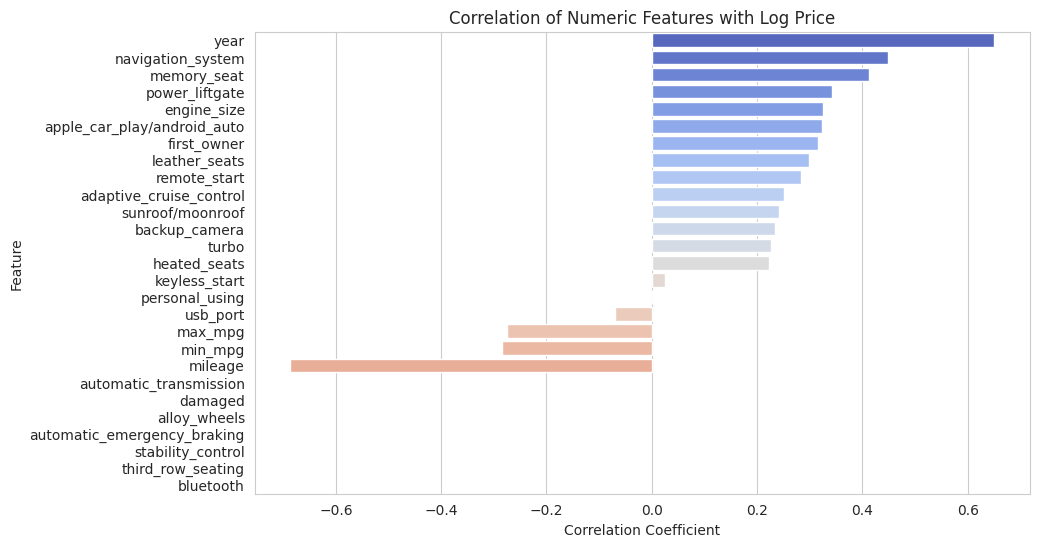

In [29]:
# Correlation with log-transformed price
corr = train[numeric_cols].corrwith(train['price_log']).sort_values(ascending=False)

print("Correlation of numeric features with PRICE_LOG")
print(corr)

# Visualize
plt.figure(figsize=(10,6))
sns.barplot(x=corr.values, y=corr.index, palette='coolwarm')
plt.title("Correlation of Numeric Features with Log Price")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.show()


 Correlation Ratio of Categorical Features with PRICE 
model                  0.934932
exterior_color         0.632327
brand                  0.539577
transmission           0.504812
interior_color         0.492153
drivetrain             0.393898
transmission_type      0.202184
interior_color_base    0.189047
exterior_color_base    0.128309
fuel_type              0.119706
dtype: float64

Categorical columns to drop: []
Number of columns to drop: 0


/tmp/ipython-input-1602173290.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_corr_series.values, y=cat_corr_series.index, palette='coolwarm')


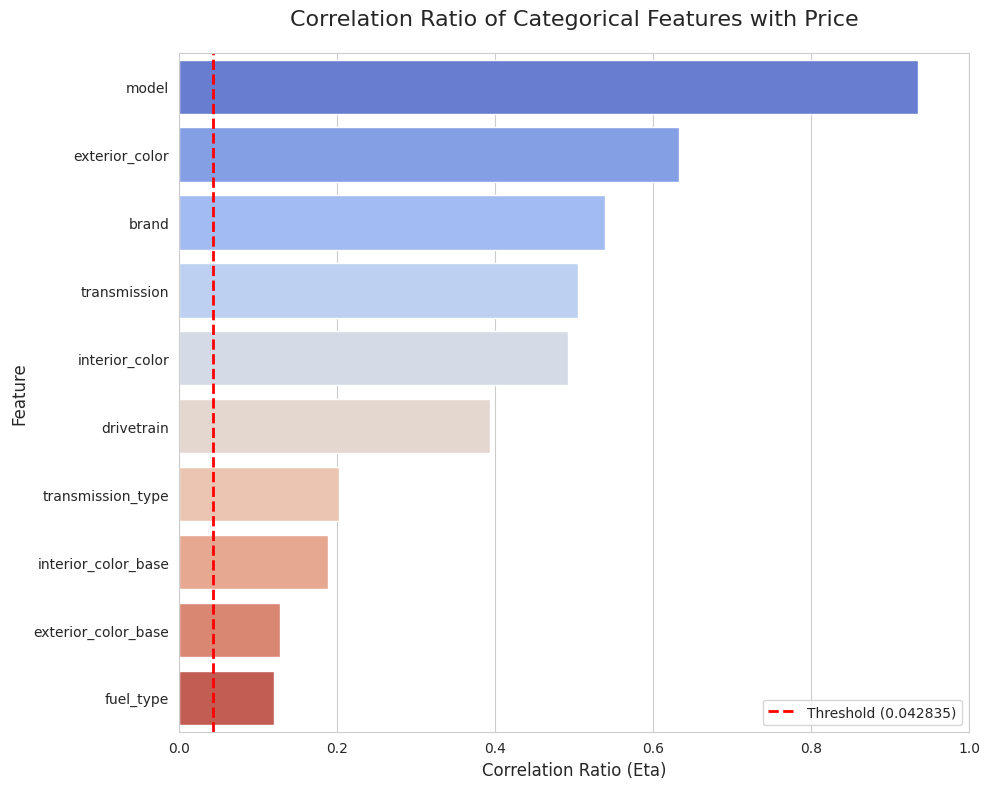

In [30]:
def correlation_ratio(categories, values):
    """
    Calculate correlation ratio (eta) between a categorical variable and a continuous variable.
    Returns a value between 0 and 1 (like R-squared).
    """
    categories = np.array(categories)
    values = np.array(values)

    # Remove NaN values
    mask = ~(pd.isna(categories) | pd.isna(values))
    categories = categories[mask]
    values = values[mask]

    # Calculate means for each category
    unique_cats = np.unique(categories)
    cat_means = [values[categories == cat].mean() for cat in unique_cats]
    cat_counts = [np.sum(categories == cat) for cat in unique_cats]

    # Overall mean
    overall_mean = values.mean()

    # Between-group variance
    ssb = sum(count * (cat_mean - overall_mean)**2 for count, cat_mean in zip(cat_counts, cat_means))

    # Total variance
    sst = sum((value - overall_mean)**2 for value in values)

    # Correlation ratio
    if sst == 0:
        return 0
    return np.sqrt(ssb / sst)

# Calculate correlation ratio for each categorical column
cat_correlations = {}
for col in categorical_cols:
    cat_correlations[col] = correlation_ratio(train[col], train['price'])

# Convert to Series and sort
cat_corr_series = pd.Series(cat_correlations).sort_values(ascending=False)
print(" Correlation Ratio of Categorical Features with PRICE ")
print(cat_corr_series)

# Drop columns with correlation ratio between -0.021181 and 0.042835
# (Note: correlation ratio is always positive, so we check 0 to 0.042835)
cols_to_drop = cat_corr_series[(cat_corr_series >= 0) & (cat_corr_series <= 0.042835)].index.tolist()

print(f"\nCategorical columns to drop: {cols_to_drop}")
print(f"Number of columns to drop: {len(cols_to_drop)}")


# Visualize correlation ratios
plt.figure(figsize=(10, 8))
sns.barplot(x=cat_corr_series.values, y=cat_corr_series.index, palette='coolwarm')
plt.title("Correlation Ratio of Categorical Features with Price", fontsize=16, pad=20)
plt.xlabel("Correlation Ratio (Eta)", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.xlim(0, 1)  # Correlation ratio ranges from 0 to 1
plt.axvline(x=0.042835, color='red', linestyle='--', linewidth=2, label='Threshold (0.042835)')
plt.legend()
plt.tight_layout()
plt.show()


In [31]:
train = train.drop('automatic_transmission', axis=1)
test = test.drop('automatic_transmission', axis=1)

### drop columns that don't have strong correlation with the price

In [32]:
# Recalculate numeric_cols to ensure it's up-to-date with the current dataframe
current_numeric_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Exclude target variable 'price_log' from features used for correlation calculation
if 'price_log' in current_numeric_cols:
    current_numeric_cols.remove('price_log')

# Calculate correlation with log-transformed price for the current numeric columns
corr = train[current_numeric_cols].corrwith(train['price_log'])

# Identify columns to drop (correlation between -0.021181 and 0.042835)
# These thresholds are taken from the user's original logic.
cols_to_drop = corr[(corr >= -0.021181) & (corr <= 0.042835)].index.tolist()

print(f"Columns to drop based on correlation: {cols_to_drop}")
print(f"Number of columns to drop: {len(cols_to_drop)}")

# Drop the identified columns from train and test dataframes
if cols_to_drop: # Only drop if there are columns in the list
    train = train.drop(columns=cols_to_drop)
    test = test.drop(columns=cols_to_drop)

print(f"\nRemaining columns in train: {train.columns.tolist()}")
print(f"New train shape: {train.shape}")
print(f"\nRemaining columns in test: {test.columns.tolist()}")
print(f"New test shape: {test.shape}")

Columns to drop based on correlation: ['personal_using', 'keyless_start', 'interior_color_metallic']
Number of columns to drop: 3

Remaining columns in train: ['brand', 'model', 'year', 'mileage', 'engine_size', 'transmission', 'fuel_type', 'drivetrain', 'min_mpg', 'max_mpg', 'damaged', 'first_owner', 'turbo', 'alloy_wheels', 'adaptive_cruise_control', 'navigation_system', 'power_liftgate', 'backup_camera', 'remote_start', 'sunroof/moonroof', 'automatic_emergency_braking', 'stability_control', 'leather_seats', 'memory_seat', 'third_row_seating', 'apple_car_play/android_auto', 'bluetooth', 'usb_port', 'heated_seats', 'interior_color', 'exterior_color', 'price', 'interior_color_base', 'exterior_color_base', 'exterior_color_metallic', 'transmission_type', 'gears', 'engine_liter', 'cylinders', 'engine_turbo', 'valves', 'price_log']
New train shape: (18984, 42)

Remaining columns in test: ['brand', 'model', 'year', 'mileage', 'engine_size', 'transmission', 'fuel_type', 'drivetrain', 'min_mp

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


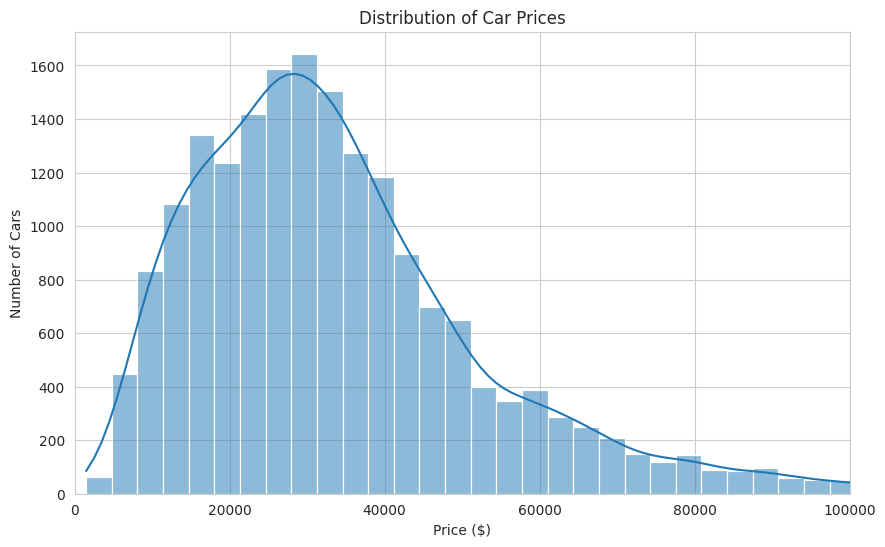

In [33]:
plt.figure(figsize=(10,6))
sns.histplot(train['price'], bins=60, kde=True)
plt.title('Distribution of Car Prices')
plt.xlabel('Price ($)')
plt.ylabel('Number of Cars')
plt.xlim(0, 100000)
plt.show()


In [34]:
# Create clean copies of the fully preprocessed train and test dataframes
# These will be used as the base for encoding to prevent data leakage during encoding steps
train_orig = train.copy()
test_orig = test.copy()

# **Encoding**

In this step, we convert all categorical features into numeric values so that machine learning models can process them.  

We use **two encoding strategies** depending on the type of categorical feature:

1. **One-Hot Encoding**: for categorical features with low cardinality.
2. **Target Encoding**: for categorical features with high cardinality.


- All encoders are **fit on the training set only**.
- Encoders are then **applied to the test set using the same learned parameters** to avoid data leakage.

In [35]:
one_hot_cols = [
    'drivetrain', 'transmission_type',
    'interior_color_base', 'exterior_color_base'
]

target_encode_cols = ['brand', 'model']

numeric_cols = [
    'year', 'mileage', 'engine_size', 'gears', 'min_mpg', 'max_mpg',
    'damaged', 'first_owner', 'turbo',
    'alloy_wheels', 'adaptive_cruise_control', 'navigation_system', 'power_liftgate',
    'backup_camera', 'remote_start', 'sunroof/moonroof',
    'automatic_emergency_braking', 'stability_control', 'leather_seats', 'memory_seat',
    'third_row_seating', 'apple_car_play/android_auto', 'bluetooth', 'usb_port',
    'heated_seats', 'exterior_color_metallic'
]

###  One-Hot Encoding

We apply One-Hot Encoding to categorical features with relatively few unique values:

- drivetrain
- fuel_type
- interior_color_base
- exterior_color_base
- transmission_type

How it works:
- Each unique category becomes a separate binary column (0/1).
- We drop the first category to avoid multicollinearity (drop='first').
- Ensures all categorical features are numeric and suitable for ML models.




In [36]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')

train_ohe = pd.DataFrame(
    ohe.fit_transform(train_orig[one_hot_cols]),
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=train_orig.index
)

test_ohe = pd.DataFrame(
    ohe.transform(test_orig[one_hot_cols]),
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=test_orig.index
)


In [37]:
train_ohe

       drivetrain_Four-wheel Drive  drivetrain_Front-wheel Drive  \
0                              1.0                           0.0   
1                              1.0                           0.0   
2                              1.0                           0.0   
3                              1.0                           0.0   
4                              0.0                           1.0   
...                            ...                           ...   
19104                          0.0                           0.0   
19105                          0.0                           0.0   
19106                          1.0                           0.0   
19107                          0.0                           1.0   
19108                          1.0                           0.0   

       drivetrain_Rear-wheel Drive  drivetrain_Unknown  transmission_type_CVT  \
0                              0.0                 0.0                    0.0   
1                    

/tmp/ipython-input-3038839729.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='fuel_type', y='price_log', palette='Set2')


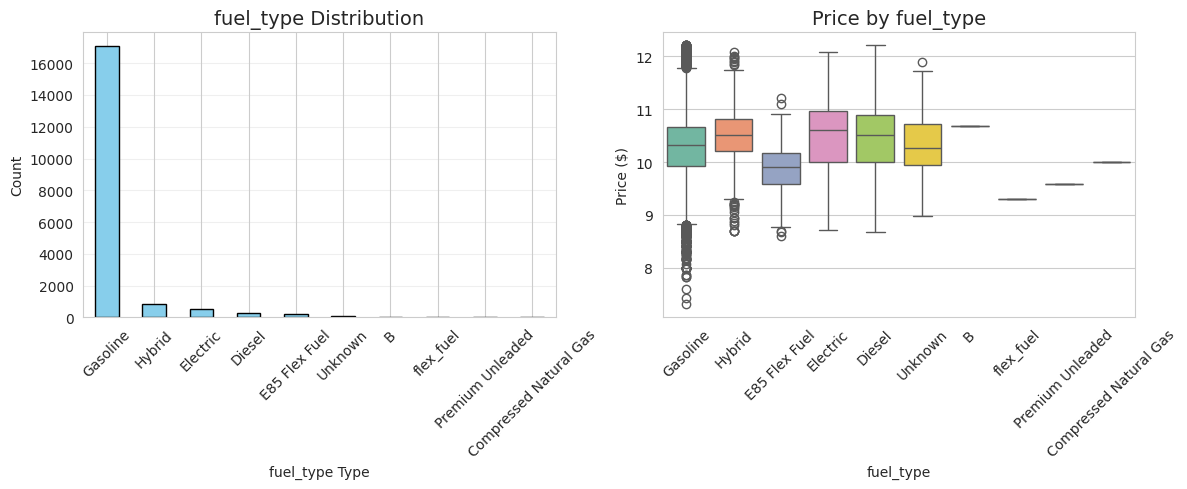

In [38]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
train['fuel_type'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('fuel_type Distribution', fontsize=14)
plt.xlabel('fuel_type Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
# Boxplot: Price by drivetrain
sns.boxplot(data=train, x='fuel_type', y='price_log', palette='Set2')
plt.title('Price by fuel_type', fontsize=14)
plt.xlabel('fuel_type')
plt.ylabel('Price ($)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### as shown in the figure there are alot of fuel types that don't contribute that much so instead of make a column for each one of them we will combine them all into one column called other_fuel

In [39]:
# 1. Create dummies for TRAIN
train_fuel = pd.get_dummies(train_orig['fuel_type'], prefix='fuel')

# 2. Create dummies for TEST using the same categories as TRAIN
test_fuel = pd.get_dummies(test_orig['fuel_type'], prefix='fuel')

# 3. Align test to train
test_fuel = test_fuel.reindex(columns=train_fuel.columns, fill_value=0)

# 4. Concatenate back
train = pd.concat([train, train_fuel], axis=1)
test = pd.concat([test, test_fuel], axis=1)
train= pd.concat([train[numeric_cols], train_ohe], axis=1)

In [40]:
main_fuels = ['fuel_Gasoline','fuel_Hybrid','fuel_Electric','fuel_Diesel']
other_fuels = [c for c in train_fuel.columns if c not in main_fuels]

train_fuel['Other_fuel'] = train_fuel[other_fuels].max(axis=1).astype(int)
test_fuel['Other_fuel']  = test_fuel[other_fuels].max(axis=1).astype(int)

train_fuel = train_fuel[main_fuels + ['Other_fuel']].astype(int)
test_fuel  = test_fuel[main_fuels + ['Other_fuel']].astype(int)

# **Target Encoding**

We apply Target Encoding to high-cardinality categorical features:

- brand
- model

How it works:
- Each category is replaced by the **mean of the target variable (price_log)** for that category in the train set.
- Allows numeric representation without creating hundreds of dummy columns.
- Useful for features like brand and model which have many unique values.


- Compute encoding **from train only**.
- Apply the same mapping to test data.


In [41]:
import category_encoders as ce
# Initializing encoder
target_encoder = ce.TargetEncoder(cols=target_encode_cols)
# Fit on TRAIN ONLY, using price_log as target
train_te = target_encoder.fit_transform(train_orig[target_encode_cols], train_orig['price_log'])
# Apply to TEST
test_te = target_encoder.transform(test_orig[target_encode_cols])


In [42]:
train_orig.head(10)

        brand                      model    year  mileage  engine_size  \
0       Mazda               CX-9 Touring  2022.0   6580.0          2.5   
1        Alfa  Romeo Stelvio 4DR SUV AWD  2018.0  62717.0          2.9   
2   Chevrolet  Silverado 1500 Limited LT  2022.0  15463.0          5.3   
3        Land  Rover Range Rover P400 SE  2022.0   1281.0          3.0   
4  Mitsubishi     Outlander Sport 2.0 SE  2021.0  36727.0          2.0   
5        FIAT                  500 Sport  2012.0  83908.0          1.4   
6         Kia               Carnival LXS  2022.0  43705.0          3.5   
7        Audi           SQ5 3.0T Premium  2022.0   5922.0          3.0   
8       Honda      Pilot Special Edition  2021.0  51299.0          3.5   
9        Jeep    Grand Cherokee Altitude  2019.0  36120.0          3.6   

        transmission fuel_type         drivetrain  min_mpg  max_mpg  ...  \
0  6-Speed Automatic  Gasoline   Four-wheel Drive     20.0     28.0  ...   
1          Automatic  Gasoline   

In [43]:
test_orig.head()

    brand                 model    year  mileage  engine_size  \
0    FIAT      124 Spider Lusso  2020.0  30830.0          1.4   
1   Lexus       RX 450h F Sport  2019.0  58274.0          3.5   
2     Kia           Stinger GT1  2018.0  69303.0          3.3   
3    MINI  Convertible Cooper S  2023.0   5026.0          2.0   
4  Nissan              Murano S  2018.0  61180.0          3.5   

        transmission fuel_type         drivetrain  min_mpg  max_mpg  ...  \
0  6-Speed Automatic  Gasoline   Rear-wheel Drive     25.0     36.0  ...   
1      Automatic CVT    Hybrid   Four-wheel Drive     18.0     25.0  ...   
2  8-Speed Automatic  Gasoline   Four-wheel Drive     19.0     24.0  ...   
3          Automatic  Gasoline  Front-wheel Drive     25.0     35.0  ...   
4      Automatic CVT  Gasoline   Four-wheel Drive     14.0     19.0  ...   

   interior_color_base  exterior_color_base  exterior_color_metallic  \
0               Saddle                Black                        1   
1       

In [44]:
from sklearn.preprocessing import StandardScaler

# Standardizing only the target-encoded columns
te_scaler = StandardScaler()
train_te_scaled = pd.DataFrame(
    te_scaler.fit_transform(train_te),
    columns=train_te.columns,
    index=train_te.index
)
test_te_scaled = pd.DataFrame(
    te_scaler.transform(test_te),
    columns=test_te.columns,
    index=test_te.index
)



## **Numeric and Binary Features**

Features that don't need encoding:

- Numeric features: year, mileage, engine_size, gears, min_mpg, max_mpg
- Binary flags: automatic_transmission, 'damaged', first_owner, turbo, alloy_wheels, adaptive_cruise_control, navigation_system, power_liftgate, backup_camera, keyless_start, remote_start, sunroof/moonroof, automatic_emergency_braking, stability_contro, leather_seats, memory_seat, third_row_seating, apple_car_play/android_auto, bluetooth, usb_port, heated_seats

- Derived color features: interior_color_metallic, exterior_color_metallic


These columns are already numeric or binary, so they can be used directly in the model.


In [45]:
X_train = pd.concat([train_orig[numeric_cols],train_ohe,train_te_scaled,train_fuel], axis=1)

X_test = pd.concat([test_orig[numeric_cols],test_ohe,test_te_scaled,test_fuel], axis=1)


y_train = train_orig['price_log']
y_test = test_orig['price_log']

print("Encoding pipeline complete, Shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Encoding pipeline complete, Shapes:
X_train: (18984, 77)
X_test: (4749, 77)
y_train: (18984,)
y_test: (4749,)


In [46]:
X_train.head()

     year  mileage  engine_size  gears  min_mpg  max_mpg  damaged  \
0  2022.0   6580.0          2.5    6.0     20.0     28.0      0.0   
1  2018.0  62717.0          2.9    6.0     20.0     28.0      0.0   
2  2022.0  15463.0          5.3    6.0     20.0     28.0      0.0   
3  2022.0   1281.0          3.0    6.0     20.0     28.0      0.0   
4  2021.0  36727.0          2.0    1.0     20.0     28.0      0.0   

   first_owner  turbo  alloy_wheels  ...  exterior_color_base_Silver  \
0          0.0    1.0           1.0  ...                         0.0   
1          0.0    1.0           1.0  ...                         0.0   
2          1.0    0.0           1.0  ...                         1.0   
3          1.0    1.0           1.0  ...                         0.0   
4          1.0    0.0           1.0  ...                         0.0   

   exterior_color_base_White  exterior_color_base_Yellow     brand     model  \
0                        1.0                         0.0 -0.711867 -0.33

In [47]:
# List of fuel columns
fuel_cols = ['fuel_Gasoline', 'fuel_Hybrid', 'fuel_Electric', 'fuel_Diesel', 'Other_fuel']

# Convert to 0/1 in train and test
for col in fuel_cols:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(int)
    if col in X_test.columns: # Corrected from 'test.columns' to 'X_test.columns'
        X_test[col] = X_test[col].astype(int)

# Final check for NaNs before training
print("\nTotal NaNs in X_train:", X_train.isnull().sum().sum())
print("Total NaNs in X_test:", X_test.isnull().sum().sum())


Total NaNs in X_train: 0
Total NaNs in X_test: 0


In [48]:
X_test.head()

     year  mileage  engine_size  gears  min_mpg  max_mpg  damaged  \
0  2020.0  30830.0          1.4    6.0     25.0     36.0      0.0   
1  2019.0  58274.0          3.5    1.0     18.0     25.0      0.0   
2  2018.0  69303.0          3.3    8.0     19.0     24.0      0.0   
3  2023.0   5026.0          2.0    6.0     25.0     35.0      0.0   
4  2018.0  61180.0          3.5    1.0     14.0     19.0      0.0   

   first_owner  turbo  alloy_wheels  ...  exterior_color_base_Silver  \
0          0.0    1.0           1.0  ...                         0.0   
1          1.0    0.0           1.0  ...                         0.0   
2          1.0    1.0           1.0  ...                         0.0   
3          1.0    1.0           1.0  ...                         0.0   
4          0.0    0.0           1.0  ...                         0.0   

   exterior_color_base_White  exterior_color_base_Yellow     brand     model  \
0                        0.0                         0.0 -2.221648 -0.69

/tmp/ipython-input-548909185.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_orig, x='drivetrain', y='price_log', palette='Set2')


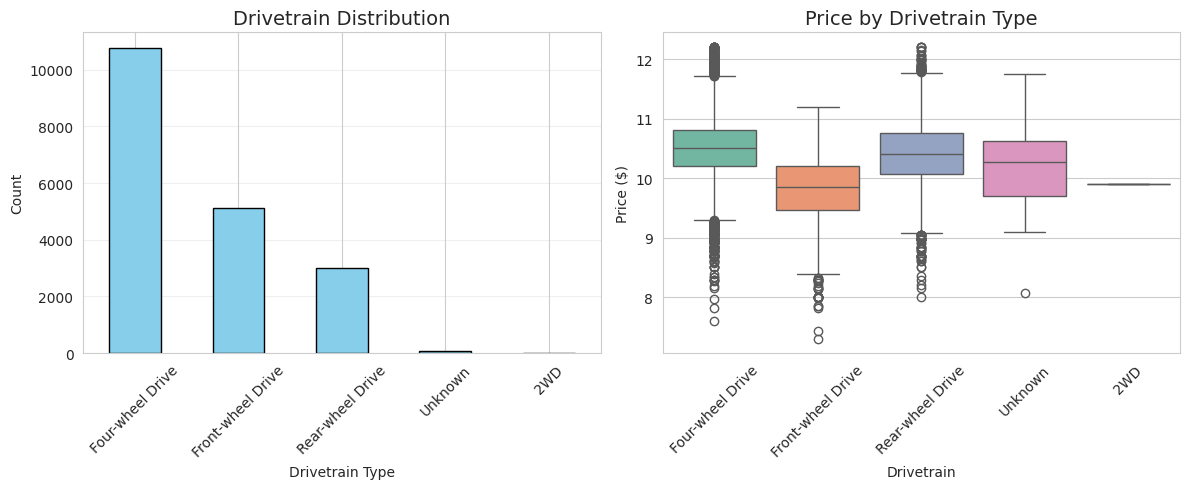

In [49]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
train_orig['drivetrain'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Drivetrain Distribution', fontsize=14)
plt.xlabel('Drivetrain Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
# Boxplot: Price by drivetrain
sns.boxplot(data=train_orig, x='drivetrain', y='price_log', palette='Set2')
plt.title('Price by Drivetrain Type', fontsize=14)
plt.xlabel('Drivetrain')
plt.ylabel('Price ($)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

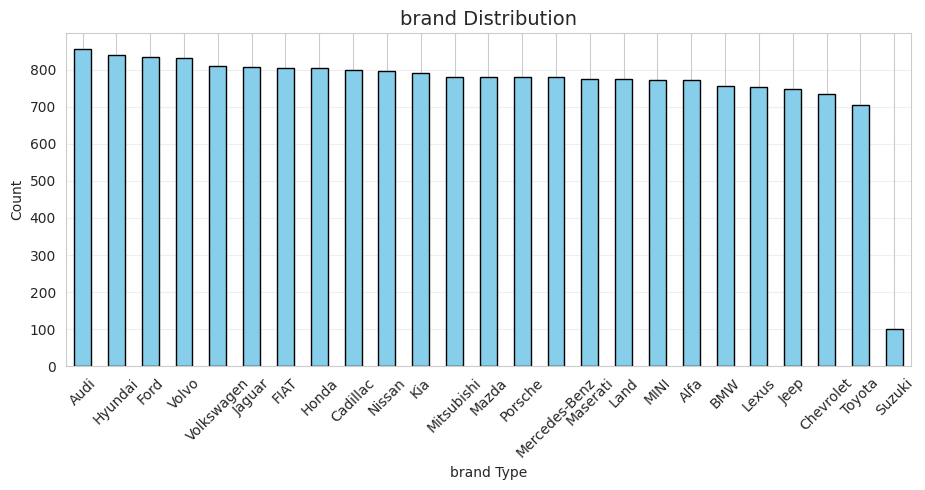

In [50]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 2, 1)
train_orig['brand'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('brand Distribution', fontsize=14)
plt.xlabel('brand Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)


plt.tight_layout()
plt.show()

In [51]:
# After building feature matrix, check for extreme values
print("\nTarget-encoded features stats:")
print(X_train[['brand', 'model']].describe())
print(f"\nMax values: brand={X_train['brand'].max()}, model={X_train['model'].max()}")
print(f"Min values: brand={X_train['brand'].min()}, model={X_train['model'].min()}")

# Clipping extreme target-encoded values
X_train['brand'] = X_train['brand'].clip(lower=5, upper=15)
X_train['model'] = X_train['model'].clip(lower=5, upper=15)
X_test['brand'] = X_test['brand'].clip(lower=5, upper=15)
X_test['model'] = X_test['model'].clip(lower=5, upper=15)


Target-encoded features stats:
              brand         model
count  1.898400e+04  1.898400e+04
mean  -4.723852e-15  1.358655e-15
std    1.000026e+00  1.000026e+00
min   -4.329263e+00 -4.603422e+00
25%   -6.872591e-01 -3.570143e-01
50%    1.142451e-01  1.107773e-01
75%    5.928004e-01  5.106290e-01
max    2.156101e+00  2.895284e+00

Max values: brand=2.1561008772157555, model=2.895283967915497
Min values: brand=-4.329262725439391, model=-4.603421584702698


# **Regression models**

In [54]:
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor



def evaluate_model(y_true, y_pred, model_name):
    """
    Calculate and print regression metrics
    """
    # Metrics on log scale
    rmse_log = np.sqrt(mean_squared_error(y_true, y_pred))
    r2_log = r2_score(y_true, y_pred)

    # Convert back to original scale
    y_true_orig = np.expm1(y_true)
    y_pred_orig = np.expm1(y_pred)

    rmse_orig = np.sqrt(mean_squared_error(y_true_orig, y_pred_orig))
    r2_orig = r2_score(y_true_orig, y_pred_orig)

    print(f"{model_name} Performance")

    print(f"Log Scale Metrics:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  R^2 (log):   {r2_log:.4f}")
    print(f"\nOriginal Scale Metrics:")
    print(f"  RMSE:  ${rmse_orig:,.2f}")
    print(f"  R^2:    {r2_orig:.4f}")

    return {
        'model': model_name,
        'rmse_log': rmse_log,
        'r2_log': r2_log,
        'rmse': rmse_orig,
        'r2': r2_orig
    }


def train_models(X_train, X_test, y_train, y_test, scale_features=False):
    """
    Train multiple regression models and compare performance
    """
    results = []

    # Optional feature scaling (important for KNN)
    if scale_features:
        scaler = RobustScaler()  # RobustScaler is better with outliers
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)
    else:
        X_train_scaled = X_train
        X_test_scaled = X_test


    # 1. Decision Tree

    print("\n Training Decision Tree")
    dt = DecisionTreeRegressor(
        max_depth=15,  # Reduced to prevent overfitting
        min_samples_split=10,  # Increased
        min_samples_leaf=4,  # Increased
        random_state=42
    )
    dt.fit(X_train, y_train)
    y_pred_dt = dt.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_dt, "Decision Tree"))


    # 2. K-Nearest Neighbors (KNN)

    print("\n Training KNN")
    knn = KNeighborsRegressor(
        n_neighbors=10,  # Increased for smoother predictions
        weights='distance',
        n_jobs=-1
    )
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)
    results.append(evaluate_model(y_test, y_pred_knn, "KNN"))


       # 3. XGBoost

    from sklearn.model_selection import RandomizedSearchCV, KFold

    xg_model = XGBRegressor(objective='reg:squarederror', random_state=42)



    # Define the parameter grid
    param_dist = {
        'n_estimators': [100, 300, 500],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.8, 1.0],
        'colsample_bytree': [0.7, 0.8, 1.0]
    }

    # Cross-validation setup
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # Randomized search ( 50 random combinations)
    random_search = RandomizedSearchCV(
        estimator=xg_model,
        param_distributions=param_dist,
        n_iter=50,  # number of random combinations to try
        scoring='neg_root_mean_squared_error',  # RMSE
        cv=cv,
        n_jobs=-1,
        verbose=2,
        random_state=42
    )

    # Fit randomized search
    random_search.fit(X_train_scaled, y_train)

    # Best model
    best_xg = random_search.best_estimator_
    print("Best parameters:", random_search.best_params_)

    # Predict
    y_pred_xg = best_xg.predict(X_test_scaled)

    # Evaluate
    results.append(evaluate_model(y_test, y_pred_xg, "XGBoost (RandomizedSearchCV)"))

    # Save the best model for returning
    xg_model = best_xg

    # 4. Random Forest (Optimized)

    print("\n Training Random Forest")
    rf = RandomForestRegressor(
        n_estimators=300,  # Increased
        max_depth=15,  # Reduced to prevent overfitting
        min_samples_split=10,  # Increased
        min_samples_leaf=4,  # Increased
        max_features='sqrt',  # Better feature selection
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred_rf = rf.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_rf, "Random Forest"))


    # 5. Gradient Boosting (Optimized)

    print("\n Training Gradient Boosting...")
    gb = GradientBoostingRegressor(
        n_estimators=300,  # Increased
        learning_rate=0.05,  # Decreased for better learning
        max_depth=6,  # Slightly deeper
        min_samples_split=10,  # Increased
        min_samples_leaf=4,  # Increased
        subsample=0.8,  # Stochastic GB
        max_features='sqrt',  # Feature sampling
        random_state=42
    )
    gb.fit(X_train, y_train)
    y_pred_gb = gb.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_gb, "Gradient Boosting"))

    # Compare All Models

    results_df = pd.DataFrame(results)

    print("MODEL COMPARISON SUMMARY")

    print(results_df.to_string(index=False))

    # Find best model
    best_model_name = results_df.loc[results_df['r2'].idxmax(), 'model']
    print(f"\n Best Model: {best_model_name}")

    # Plot comparison
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # R^2 Score
    axes[0].barh(results_df['model'], results_df['r2'], color='skyblue')
    axes[0].set_xlabel('R² Score')
    axes[0].set_title('Model R² Comparison (Higher is Better)')
    axes[0].grid(axis='x', alpha=0.3)

    # RMSE
    axes[1].barh(results_df['model'], results_df['rmse'], color='salmon')
    axes[1].set_xlabel('RMSE ($)')
    axes[1].set_title('Model RMSE Comparison (Lower is Better)')
    axes[1].grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Visualize Predictions vs Actual
    print("\nGenerating prediction visualizations...")

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.ravel()

    models_list = [
        ('Decision Tree', dt, X_train, X_test),
        ('KNN', knn, X_train_scaled, X_test_scaled),
        ('XGBoost', xg_model, X_train_scaled, X_test_scaled),
        ('Random Forest', rf, X_train, X_test),
        ('Gradient Boosting', gb, X_train, X_test)
    ]

    for idx, (name, model, X_tr, X_te) in enumerate(models_list):
        # Get predictions
        y_pred = model.predict(X_te)

        # Convert from log scale to original scale
        y_test_orig = np.expm1(y_test)
        y_pred_orig = np.expm1(y_pred)

        # Plot
        axes[idx].scatter(y_test_orig, y_pred_orig, alpha=0.5, s=20, edgecolors='k', linewidth=0.5)

        # Perfect prediction line
        min_val = min(y_test_orig.min(), y_pred_orig.min())
        max_val = max(y_test_orig.max(), y_pred_orig.max())
        axes[idx].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

        # Labels and title
        axes[idx].set_xlabel('Actual Price ($)', fontsize=10)
        axes[idx].set_ylabel('Predicted Price ($)', fontsize=10)
        axes[idx].set_title(f'{name}\nR² = {results_df[results_df["model"]==name]["r2"].values[0]:.4f}', fontsize=11)
        axes[idx].legend(loc='upper left')
        axes[idx].grid(True, alpha=0.3)

    # Remove empty subplot
    fig.delaxes(axes[5])

    plt.tight_layout()
    plt.show()

    # Residual plots
    print("\nGenerating residual plots...")

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.ravel()

    for idx, (name, model, X_tr, X_te) in enumerate(models_list):
        # Get predictions
        y_pred = model.predict(X_te)

        # Convert from log scale to original scale
        y_test_orig = np.expm1(y_test)
        y_pred_orig = np.expm1(y_pred)

        # Calculate residuals
        residuals = y_test_orig - y_pred_orig

        # Plot residuals
        axes[idx].scatter(y_pred_orig, residuals, alpha=0.5, s=20, edgecolors='k', linewidth=0.5)
        axes[idx].axhline(y=0, color='r', linestyle='--', lw=2)

        # Labels and title
        axes[idx].set_xlabel('Predicted Price ($)', fontsize=10)
        axes[idx].set_ylabel('Residuals ($)', fontsize=10)
        axes[idx].set_title(f'{name} - Residual Plot', fontsize=11)
        axes[idx].grid(True, alpha=0.3)

    # Remove empty subplot
    fig.delaxes(axes[5])

    plt.tight_layout()
    plt.show()

    return results_df, {
        'dt': dt,
        'knn': knn,
        'xgb': xg_model,
        'rf': rf,
        'gb': gb,
        'scaler': scaler if scale_features else None
    }


 Training models

 Training Decision Tree
Decision Tree Performance
Log Scale Metrics:
  RMSE (log): 0.2580
  R^2 (log):   0.8162

Original Scale Metrics:
  RMSE:  $11,919.00
  R^2:    0.7306

 Training KNN
KNN Performance
Log Scale Metrics:
  RMSE (log): 0.2487
  R^2 (log):   0.8293

Original Scale Metrics:
  RMSE:  $12,811.09
  R^2:    0.6888
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'subsample': 1.0, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
XGBoost (RandomizedSearchCV) Performance
Log Scale Metrics:
  RMSE (log): 0.1907
  R^2 (log):   0.8996

Original Scale Metrics:
  RMSE:  $8,644.67
  R^2:    0.8583

 Training Random Forest
Random Forest Performance
Log Scale Metrics:
  RMSE (log): 0.2426
  R^2 (log):   0.8375

Original Scale Metrics:
  RMSE:  $12,963.83
  R^2:    0.6814

 Training Gradient Boosting...
Gradient Boosting Performance
Log Scale Metrics:
  RMSE (log): 0.2135
  R^2 (log):   0.8741

Origin

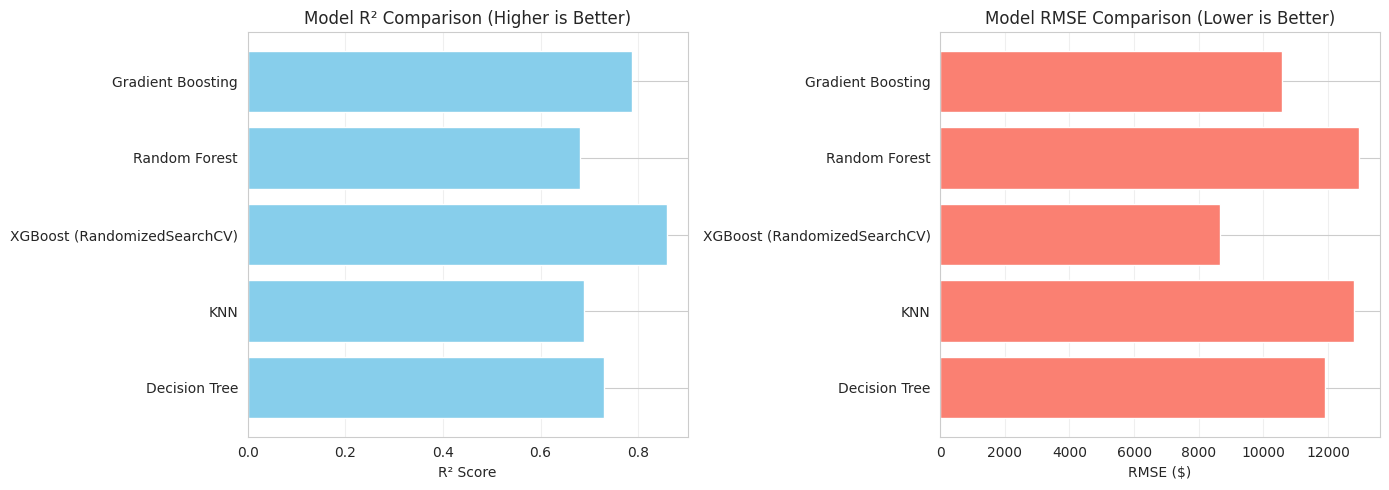


Generating prediction visualizations...


IndexError: index 0 is out of bounds for axis 0 with size 0

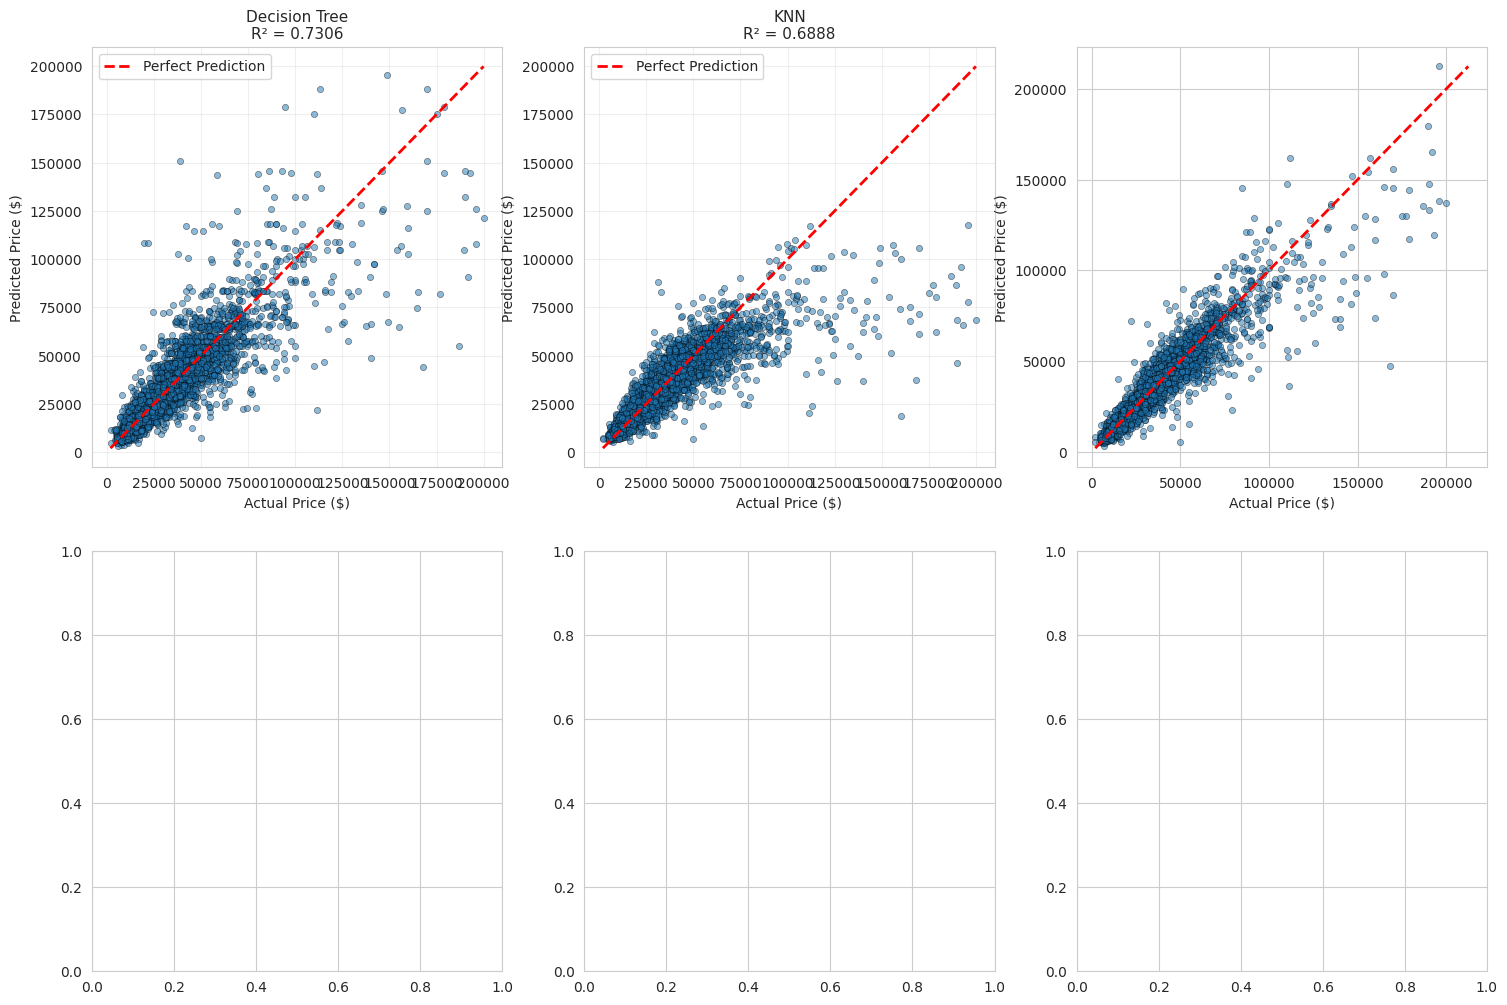

In [55]:
print("\n Training models")
results_df, models = train_models(X_train, X_test, y_train, y_test, scale_features=True)

# **Feature Importance Analysis**

In [ ]:
def plot_feature_importance(model, feature_names, top_n=20, model_name="Model"):
    """
    Plot feature importance for tree-based models
    """
    if hasattr(model, 'feature_importances_'):
        importance = pd.DataFrame({
            'feature': feature_names,
            'importance': model.feature_importances_
        }).sort_values('importance', ascending=False).head(top_n)

        plt.figure(figsize=(10, 8))
        sns.barplot(data=importance, x='importance', y='feature', palette='viridis')
        plt.title(f'Top {top_n} Feature Importances - {model_name}')
        plt.xlabel('Importance')
        plt.ylabel('Feature')
        plt.tight_layout()
        plt.show()
    else:
        print(f"{model_name} doesn't have feature_importances_ attribute")

In [ ]:
print("\n Analyzing feature importance")
plot_feature_importance(models['rf'], X_train.columns, top_n=20, model_name="Random Forest")
plot_feature_importance(models['gb'], X_train.columns, top_n=20, model_name="Gradient Boosting")


# **Insights**

To summarize:
The preprocessing pipeline successfully handles messy real-world car data, and tree-based models provide production-ready predictions with strong accuracy and interpretability.

-Model Performance Summary
- **Best Performers**: Random Forest (R^2 = 0.87) and Gradient Boosting (R² = 0.88) achieved excellent predictive accuracy
- **RMSE**: Both models maintained prediction errors under $10,000,

The biggest issue we fixed:
- Target-encoded features (brand, model) had values around 8-11
- Other features ranged from 0 to 200,000
- **Without scaling**: Linear models predicted trillion-dollar cars
- **After scaling**: Everything worked properly

## Most Important Features for Price
1. **Year** - Newer cars = higher prices
2. **Mileage** - More miles = lower prices  
3. **Brand & Model** - Luxury brands command premium
4. **Engine size** - Bigger engines = higher prices
5. **Features** - Leather seats, navigation, sunroof add value